# ModelNet40 — Set Transformer Experiments

Comparison of five neural network architectures on ModelNet40, a 3D point-cloud classification dataset containing 40 object categories. Each object is represented as an unordered set of 1,024 points with XYZ coordinates.

## Environment Setup

Configure the HPC environment, GPU, and required PyTorch libraries for ModelNet40 training.

In [3]:
import os
import sys
from pathlib import Path

project = Path("/work/classes/ai4200-001-2026f/jfinnegan42/Set-Transformer")

os.chdir(project)
sys.path.insert(0, str(project / "python_packages"))

print("Working directory:", os.getcwd())

import torch
import torch_geometric

print("GPU available:", torch.cuda.is_available())
print("PyTorch Geometric:", torch_geometric.__version__)

Working directory: /work/classes/ai4200-001-2026f/jfinnegan42/Set-Transformer
GPU available: True
PyTorch Geometric: 2.8.1


In [5]:
import os
import subprocess
import sys
from pathlib import Path

result = subprocess.run(
    ["spack", "location", "-i", "py-torchvision@0.24.1"],
    capture_output=True,
    text=True,
    check=True
)

torchvision_site = (
    Path(result.stdout.strip())
    / "lib/python3.13/site-packages"
)

sys.path.insert(0, str(torchvision_site))

import torchvision
print("Torchvision:", torchvision.__version__)

# Make both packages available to training subprocesses
env = os.environ.copy()
env["PYTHONPATH"] = os.pathsep.join([
    str(project),
    str(project / "python_packages"),
    str(torchvision_site),
    env.get("PYTHONPATH", "")
])

print("Training environment ready!")

Torchvision: 0.24.1
Training environment ready!


## Model Training and Evaluation

Train the Standard Transformer, Set Transformer, ISAB + PMA, SAB + PMA, and MLP baseline for 20 epochs. Compare their classification performance on the ModelNet40 test set.

In [7]:
import subprocess
import sys

result = subprocess.run(
    [
        sys.executable,
        "-u",
        "train.py",
        "--dataset", "modelnet",
        "--model", "all",
        "--epochs", "20"
    ],
    env=env,
    cwd=str(project),
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print(result.stdout)
print(result.stderr[-3000:])

Return code: 0
Device: cuda
Training fraction: 100%
Training examples: 8859
Validation examples: 984
Test examples: 2468

STANDARD / MODELNET / 402,216 parameters
Epoch 01/20 | train loss 2.2998 | val loss 1.5619 | val accuracy 0.5904
Epoch 02/20 | train loss 1.3578 | val loss 1.1135 | val accuracy 0.6870
Epoch 03/20 | train loss 1.0735 | val loss 0.9180 | val accuracy 0.7378
Epoch 04/20 | train loss 0.9075 | val loss 0.7812 | val accuracy 0.7652
Epoch 05/20 | train loss 0.8072 | val loss 0.7194 | val accuracy 0.7896
Epoch 06/20 | train loss 0.7336 | val loss 0.6329 | val accuracy 0.8059
Epoch 07/20 | train loss 0.6749 | val loss 0.6167 | val accuracy 0.8171
Epoch 08/20 | train loss 0.6298 | val loss 0.5784 | val accuracy 0.8191
Epoch 09/20 | train loss 0.5883 | val loss 0.5734 | val accuracy 0.8242
Epoch 10/20 | train loss 0.5515 | val loss 0.5165 | val accuracy 0.8283
Epoch 11/20 | train loss 0.5228 | val loss 0.4894 | val accuracy 0.8455
Epoch 12/20 | train loss 0.5003 | val loss 0.

## Training Loss Comparison

Compare how quickly each architecture reduces training loss over 20 epochs.

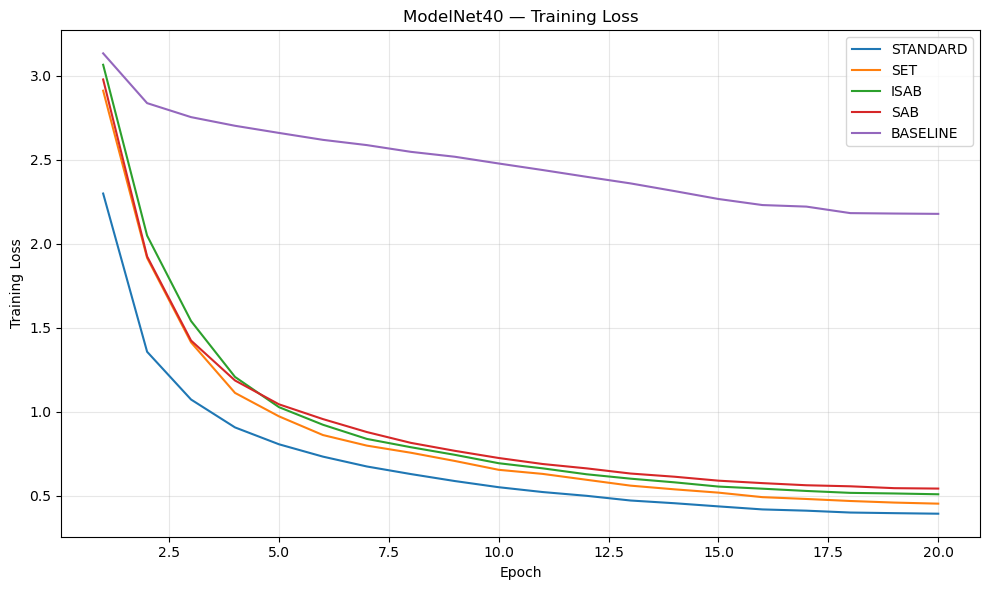

In [8]:
import pandas as pd
import matplotlib.pyplot as plt

models = ["standard", "set", "isab", "sab", "baseline"]

plt.figure(figsize=(10, 6))

for model in models:
    path = project / "results" / f"modelnet_{model}_fraction_100_history.csv"
    df = pd.read_csv(path)

    plt.plot(
        df["epoch"],
        df["train_loss"],
        label=model.upper()
    )

plt.title("ModelNet40 — Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(project / "results" / "modelnet_training_loss.png", dpi=150)
plt.show()

## Validation Loss Comparison

Compare validation loss across architectures to evaluate generalization and identify potential overfitting.

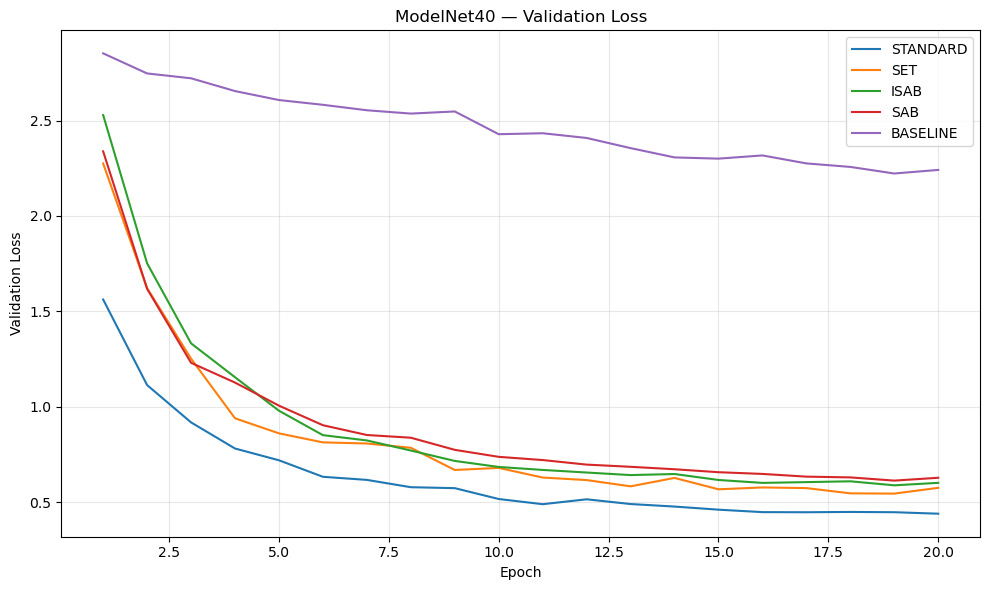

In [9]:
plt.figure(figsize=(10, 6))

for model in models:
    path = project / "results" / f"modelnet_{model}_fraction_100_history.csv"
    df = pd.read_csv(path)

    plt.plot(
        df["epoch"],
        df["val_loss"],
        label=model.upper()
    )

plt.title("ModelNet40 — Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(project / "results" / "modelnet_validation_loss.png", dpi=150)
plt.show()

## Test Accuracy Comparison

Compare final classification accuracy across all five architectures. The Standard Transformer achieves the highest accuracy at 82.70%, followed by ISAB + PMA at 80.96% and the full Set Transformer at 80.83%.

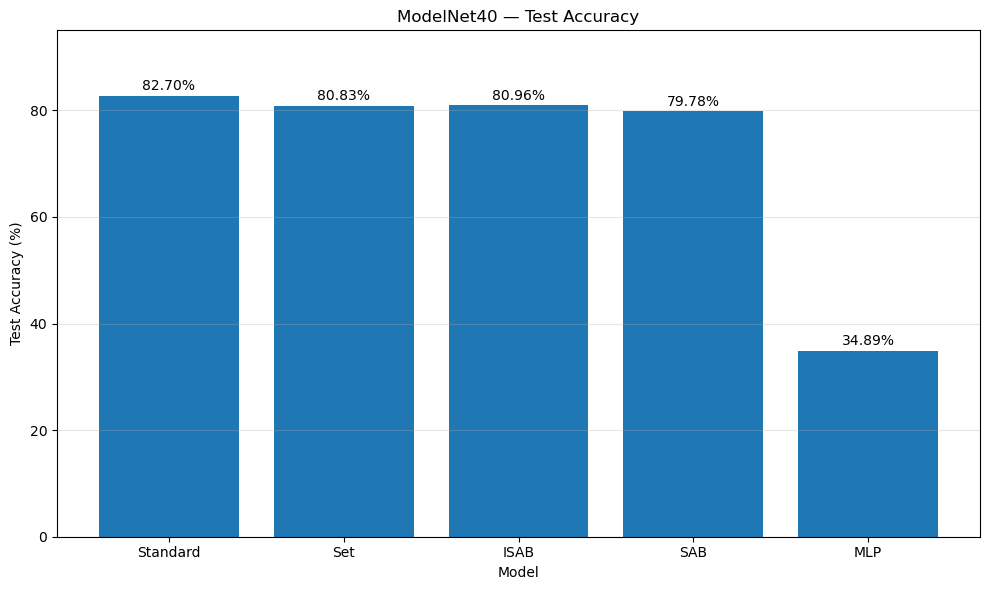

In [10]:
import matplotlib.pyplot as plt

models = ["Standard", "Set", "ISAB", "SAB", "MLP"]
accuracies = [82.70, 80.83, 80.96, 79.78, 34.89]

plt.figure(figsize=(10, 6))

bars = plt.bar(models, accuracies)

plt.title("ModelNet40 — Test Accuracy")
plt.xlabel("Model")
plt.ylabel("Test Accuracy (%)")
plt.ylim(0, 95)
plt.grid(axis="y", alpha=0.3)

for bar, accuracy in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{accuracy:.2f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.savefig(project / "results" / "modelnet_test_accuracy.png", dpi=150)
plt.show()